# Exercise 4 - Spherical collapse



Three numerical formulations

All the physics lives in the .py files: cosmology.py (background), form_A.py, form_B.py, form_C.py (the three independent
systems) and collapse.py (shooting, turnaround, virial prescription). run_all.py reproduces every table and figure in output/;
this notebook calls the same functions.


In [5]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp

from cosmology import Cosmology
from collapse import collapse, integrate, virial_y, DELTA_C_EDS
import form_A, form_B, form_C
from run_all import (FORMS, A_I, DELTA_INF, RTOL, EDS_TARGETS, threshold, run,
                     eds_benchmarks, cosmology_grid, convergence, cross_differences,
                     plot_grid, plot_convergence)

print(f'Fiducial settings: a_i = {A_I}, delta_inf = {DELTA_INF:.0e} (C: eps = {1/DELTA_INF:.0e}), rtol = {RTOL}, atol = rtol * a_i * 1e-2')

Fiducial settings: a_i = 1e-05, delta_inf = 1e+08 (C: eps = 1e-08), rtol = 1e-10, atol = rtol * a_i * 1e-2


### a) Three independent systems

$A_H = 2 + d\ln H/dN$, $\vartheta = \nabla_x\cdot\mathbf{v}/(aH)$, $g = 1/\delta$. Each formulation integrates its own variables:
**A** $(\delta, \delta_N)$, **B** $(\delta, \vartheta)$, **C** $(g, \vartheta)$.


In [6]:
cosmo = Cosmology(0.3)
rng = np.random.default_rng(0)
worst = 0
for _ in range(1000): # random physical states
    N, d, th = np.log(rng.uniform(1e-3, 1)), 10**rng.uniform(-3, 4), -10**rng.uniform(-3, 3)
    dN = -(1 + d) * th # continuity
    rA = form_A.rhs(N, [d, dN, 0, 0], cosmo) # delta_NN
    rB = form_B.rhs(N, [d, th, 0, 0], cosmo) # delta_N, theta_N
    rC = form_C.rhs(N, [1 / d, th, 0, 0], cosmo) # g_N, theta_N
    dNN_from_B = -rB[0] * th - (1 + d) * rB[1] # d/dN of -(1+delta) theta
    gN_from_A = -dN / d**2 # d/dN of 1/delta
    worst = max(worst, abs(rA[1] / dNN_from_B - 1), abs(rC[0] / gN_from_A - 1), abs(rC[1] / rB[1] - 1))
print(f'max relative mismatch between A, B and C right-hand sides: {worst:.1e}')

max relative mismatch between A, B and C right-hand sides: 7.5e-15


### b & c) Growing mode, shooting and the collapse of each formulation

Initial conditions at $a_i$: $\delta_{N,i} = f_i\delta_i$, $\vartheta_i = -f_i\delta_i/(1+\delta_i)$, $g_i = 1/\delta_i$, with $f_i$ from exercise 1.


$\delta_i$ is tuned (root search on the collapse epoch) until the terminal event happens at $a_c$: $\delta = \delta_\infty$ for A and B,
$g = \epsilon$ for C. Then $\delta_c = \delta_L(a_c)$.


In [7]:
a_c, atol = 1.0, RTOL * A_I * 1e-2
res, sols = {}, {}
for F in FORMS:
    res[F.name] = run(F, cosmo, 0) # flat LCDM, Om0 = 0.3, z_c = 0
    sols[F.name] = integrate(F, cosmo, res[F.name]['delta_i'], A_I, a_c * np.exp(0.5),
                             threshold(F, DELTA_INF), RTOL, atol) # same run, to plot the trajectory
    r = res[F.name]
    print(f"{F.name}: delta_i = {r['delta_i']:.10e}  bracket = ({r['bracket'][0]:.2e}, {r['bracket'][1]:.2e})  "
          f"event residual = {r['event_residual']:.1e}  delta_c = {r['delta_c']:.8f}")

def markers(ax, r):
    ax.axvline(r['a_ta'], color='gray', ls=':', label='turnaround')
    ax.axvline(r['a_c'], color='k', ls=':', label='collapse')

A: delta_i = 2.1508359780e-05  bracket = (8.43e-06, 3.37e-05)  event residual = -8.5e-16  delta_c = 1.67546040
B: delta_i = 2.1508359780e-05  bracket = (8.43e-06, 3.37e-05)  event residual = -3.1e-15  delta_c = 1.67546040
C: delta_i = 2.1508359778e-05  bracket = (8.43e-06, 3.37e-05)  event residual = 1.7e-15  delta_c = 1.67546040


### Formulation A

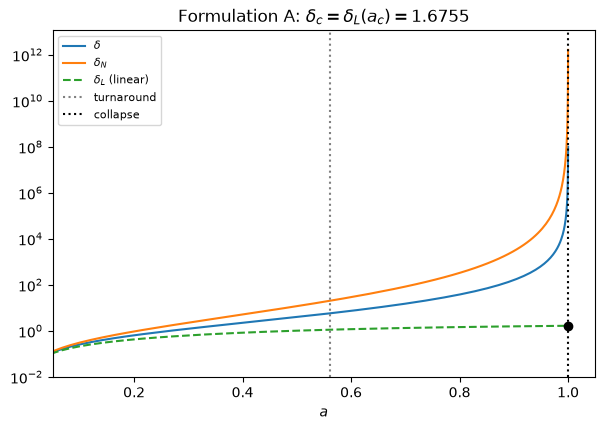

In [8]:
r, s = res['A'], sols['A']; a = np.exp(s.t)
fig, ax = plt.subplots(figsize=(7, 4.5))
ax.semilogy(a, s.y[0], label=r'$\delta$')
ax.semilogy(a, s.y[1], label=r'$\delta_N$')
ax.semilogy(a, s.y[2], '--', label=r'$\delta_L$ (linear)')
markers(ax, r); ax.plot(r['a_c'], r['delta_c'], 'ko')
ax.set_xlim(0.05, 1.05); ax.set_ylim(1e-2, None)
ax.set_xlabel('$a$'); ax.set_title(rf"Formulation A: $\delta_c = \delta_L(a_c) = {r['delta_c']:.4f}$"); ax.legend(fontsize=8)
plt.show()

### Formulation B

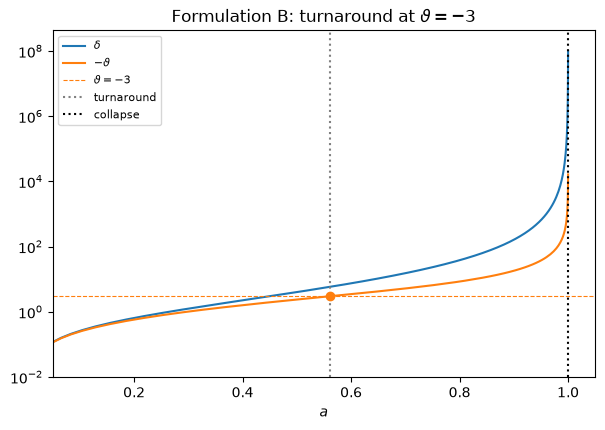

In [9]:
r, s = res['B'], sols['B']; a = np.exp(s.t)
fig, ax = plt.subplots(figsize=(7, 4.5))
ax.semilogy(a, s.y[0], label=r'$\delta$')
ax.semilogy(a, -s.y[1], label=r'$-\vartheta$')
ax.axhline(3, color='C1', ls='--', lw=0.8, label=r'$\vartheta = -3$')
markers(ax, r); ax.plot(r['a_ta'], 3, 'o', color='C1')
ax.set_xlim(0.05, 1.05); ax.set_ylim(1e-2, None)
ax.set_xlabel('$a$'); ax.set_title(r'Formulation B: turnaround at $\vartheta = -3$'); ax.legend(fontsize=8)
plt.show()

### Formulation C

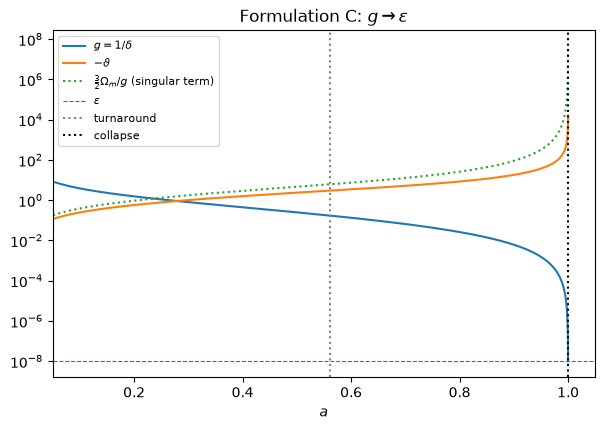

In [10]:
r, s = res['C'], sols['C']; a = np.exp(s.t)
fig, ax = plt.subplots(figsize=(7, 4.5))
ax.semilogy(a, s.y[0], label=r'$g = 1/\delta$')
ax.semilogy(a, -s.y[1], label=r'$-\vartheta$')
ax.semilogy(a, 1.5 * cosmo.Om(a) / s.y[0], ':', label=r'$\frac{3}{2}\Omega_m/g$ (singular term)')
ax.axhline(1 / DELTA_INF, color='C0', ls='--', lw=0.8, label=r'$\epsilon$')
markers(ax, r)
ax.set_xlim(0.05, 1.05)
ax.set_xlabel('$a$'); ax.set_title(r'Formulation C: $g \to \epsilon$'); ax.legend(fontsize=8)
plt.show()

All three reach the same collapse through different variables. In A, $\delta_N$ diverges together with $\delta$. In B, the turnaround is read directly from $\vartheta = -3$.
In C, $g$ goes to zero instead of diverging, but $\vartheta$ and the $1/g$ term still blow up, so no formulation removes the singularity.

### Agreement between formulations and the shooting

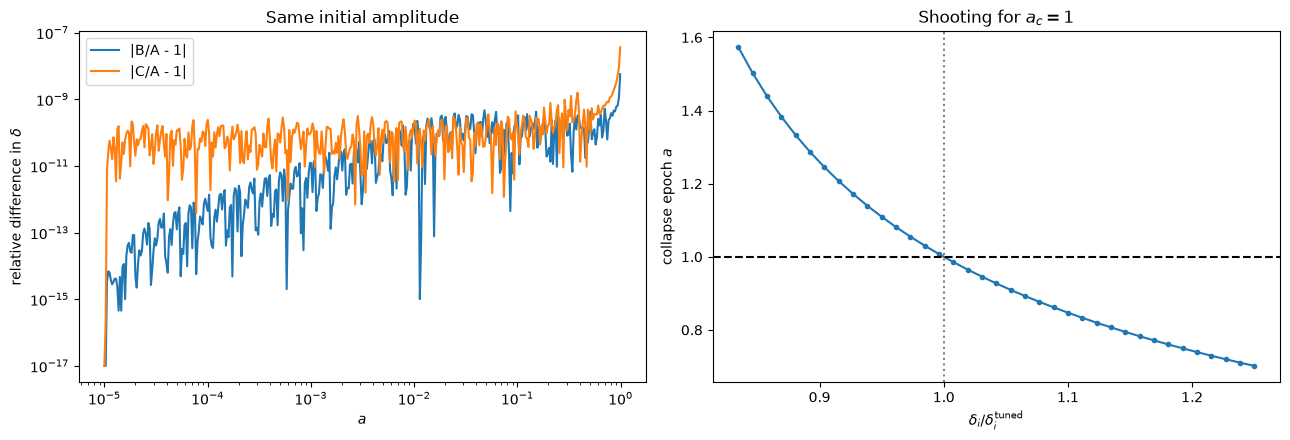

In [11]:
# Same delta_i integrated by each formulation on a common grid (stopping before collapse)
N_eval = np.linspace(np.log(A_I), np.log(0.99), 400)
d_of = {}
for F in FORMS:
    s = solve_ivp(F.rhs, (N_eval[0], N_eval[-1]), F.initial_state(res['A']['delta_i'], cosmo.f(A_I)[0]),
                  args=(cosmo,), method='DOP853', rtol=RTOL, atol=atol, t_eval=N_eval)
    d_of[F.name] = np.array([F.delta(s.y[:, j]) for j in range(s.y.shape[1])])

# Collapse epoch as a function of delta_i (formulation A)
di0 = res['A']['delta_i']
scan = di0 * np.linspace(0.8, 1.25, 40)
a_coll = []
for d in scan:
    s = integrate(form_A, cosmo, d, A_I, a_c * np.exp(0.5), DELTA_INF, RTOL, atol)
    a_coll.append(np.exp(s.t_events[0][0]) if len(s.t_events[0]) else np.nan)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.5))
ax1.loglog(np.exp(N_eval), np.abs(d_of['B'] / d_of['A'] - 1) + 1e-17, label='|B/A - 1|')
ax1.loglog(np.exp(N_eval), np.abs(d_of['C'] / d_of['A'] - 1) + 1e-17, label='|C/A - 1|')
ax1.set_xlabel('$a$'); ax1.set_ylabel(r'relative difference in $\delta$'); ax1.set_title('Same initial amplitude'); ax1.legend()
ax2.plot(scan / di0, a_coll, 'o-', ms=3); ax2.axhline(a_c, color='k', ls='--'); ax2.axvline(1, color='gray', ls=':')
ax2.set_xlabel(r'$\delta_i / \delta_i^\mathrm{tuned}$'); ax2.set_ylabel('collapse epoch $a$'); ax2.set_title(r'Shooting for $a_c = 1$')
fig.tight_layout(); plt.show()

### d) Turnaround and virial prescription

Turnaround at $\vartheta_\mathrm{ta} = -3$, with $\zeta_\mathrm{ta} = 1+\delta(a_\mathrm{ta})$. 


The ratio $y = R_\mathrm{vir}/R_\mathrm{ta}$ is the root of $4\lambda_\mathrm{ta}y^3 - 2(1+\lambda_\mathrm{ta})y + 1 = 0$
connected to $1/2$ as $\lambda_\mathrm{ta}\to 0$, where $\lambda_\mathrm{ta} = \rho_\Lambda/\rho_\mathrm{sph,ta}$.

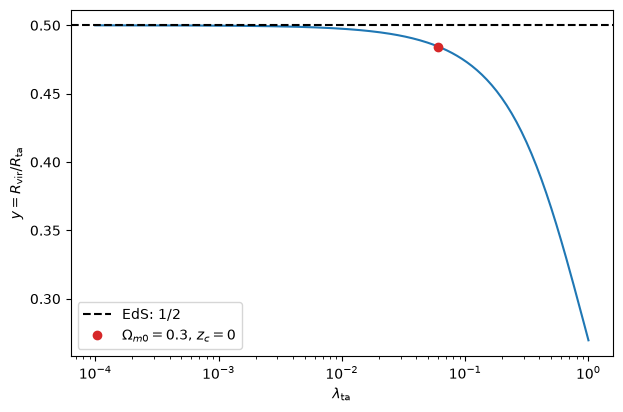

A: a_ta = 0.56146  zeta_ta = 6.8373  lambda_ta = 0.0604  y = 0.4845  Delta_vir,m = 339.71  Delta_vir,c = 101.91
B: a_ta = 0.56146  zeta_ta = 6.8373  lambda_ta = 0.0604  y = 0.4845  Delta_vir,m = 339.71  Delta_vir,c = 101.91
C: a_ta = 0.56146  zeta_ta = 6.8373  lambda_ta = 0.0604  y = 0.4845  Delta_vir,m = 339.71  Delta_vir,c = 101.91


In [12]:
lam = np.logspace(-4, 0, 200)
r = res['A']
fig, ax = plt.subplots(figsize=(7, 4.5))
ax.semilogx(lam, [virial_y(l) for l in lam])
ax.axhline(0.5, color='k', ls='--', label='EdS: 1/2')
ax.plot(r['lambda_ta'], r['y'], 'o', color='C3', label=rf"$\Omega_{{m0}}=0.3$, $z_c=0$")
ax.set_xlabel(r'$\lambda_\mathrm{ta}$'); ax.set_ylabel(r'$y = R_\mathrm{vir}/R_\mathrm{ta}$'); ax.legend()
plt.show()

for F in FORMS:
    r = res[F.name]
    print(f"{F.name}: a_ta = {r['a_ta']:.5f}  zeta_ta = {r['zeta_ta']:.4f}  lambda_ta = {r['lambda_ta']:.4f}  y = {r['y']:.4f}  "
          f"Delta_vir,m = {r['Dvir_m']:.2f}  Delta_vir,c = {r['Dvir_c']:.2f}")

### e) EdS benchmarks

In [13]:
print('targets: delta_c = %.5f, a_ta/a_c = %.5f, zeta_ta = %.4f, Delta_vir = %.2f' % tuple(EDS_TARGETS.values()))
for r in eds_benchmarks():
    print(f"{r['formulation']} z_c={r['z_c']}: delta_c = {r['delta_c']:.5f}  a_ta/a_c = {r['ata_ac']:.5f}  "
          f"zeta_ta = {r['zeta_ta']:.4f}  Delta_vir,m = {r['Dvir_m']:.2f}")

targets: delta_c = 1.68647, a_ta/a_c = 0.62996, zeta_ta = 5.5517, Delta_vir = 177.65
A z_c=0: delta_c = 1.68639  a_ta/a_c = 0.63000  zeta_ta = 5.5517  Delta_vir,m = 177.62
B z_c=0: delta_c = 1.68639  a_ta/a_c = 0.63000  zeta_ta = 5.5517  Delta_vir,m = 177.62
C z_c=0: delta_c = 1.68639  a_ta/a_c = 0.63000  zeta_ta = 5.5517  Delta_vir,m = 177.62
A z_c=1: delta_c = 1.68642  a_ta/a_c = 0.63000  zeta_ta = 5.5517  Delta_vir,m = 177.62
B z_c=1: delta_c = 1.68642  a_ta/a_c = 0.63000  zeta_ta = 5.5517  Delta_vir,m = 177.62
C z_c=1: delta_c = 1.68642  a_ta/a_c = 0.63000  zeta_ta = 5.5517  Delta_vir,m = 177.62
A z_c=2: delta_c = 1.68645  a_ta/a_c = 0.63000  zeta_ta = 5.5517  Delta_vir,m = 177.62
B z_c=2: delta_c = 1.68645  a_ta/a_c = 0.63000  zeta_ta = 5.5517  Delta_vir,m = 177.62
C z_c=2: delta_c = 1.68645  a_ta/a_c = 0.63000  zeta_ta = 5.5517  Delta_vir,m = 177.62


### f) Cosmology grid

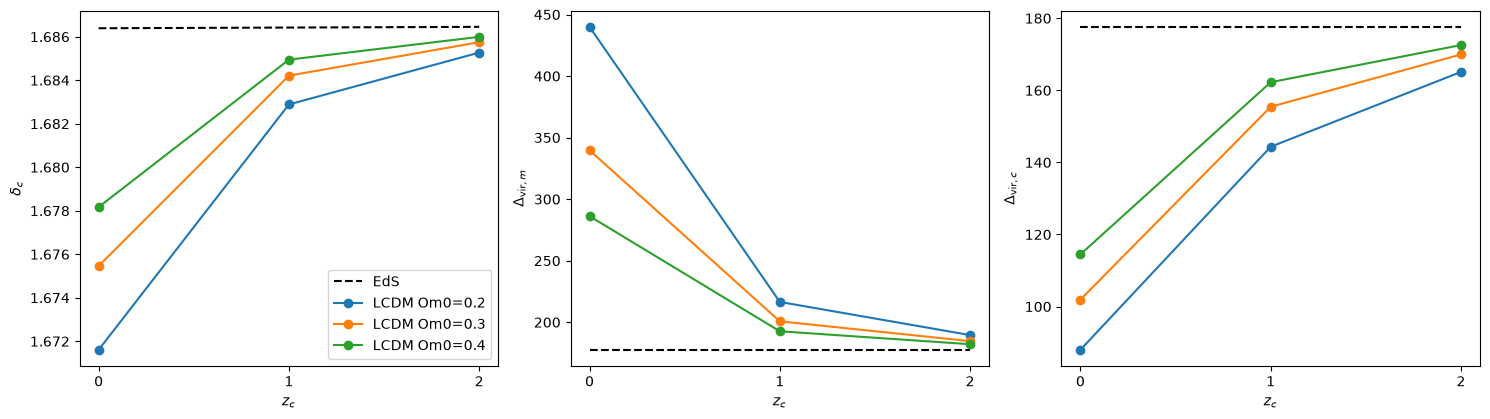

In [14]:
grid = cosmology_grid()
plot_grid(grid, save=False); plt.show()

All quantities tend to EdS at high $z_c$, when $\Lambda$ is negligible. At low $z_c$ (and low $\Omega_{m0}$):
- **growth:** $\Lambda$ slows down the growth, so $\delta_c$ is a bit below the EdS value;
- **turnaround:** happens earlier relative to collapse and at a higher $\zeta_\mathrm{ta}$;
- **virial prescription:** $\Lambda$ makes $y < 1/2$, so the halo is more compact;
- **reference density:** $\Delta_{\mathrm{vir},m}$ grows well above $18\pi^2$, while $\Delta_{\mathrm{vir},c} = \Omega_m(a_c)\Delta_{\mathrm{vir},m}$ falls below it, since the mean matter density is only a fraction of the critical one.

### g) Convergence

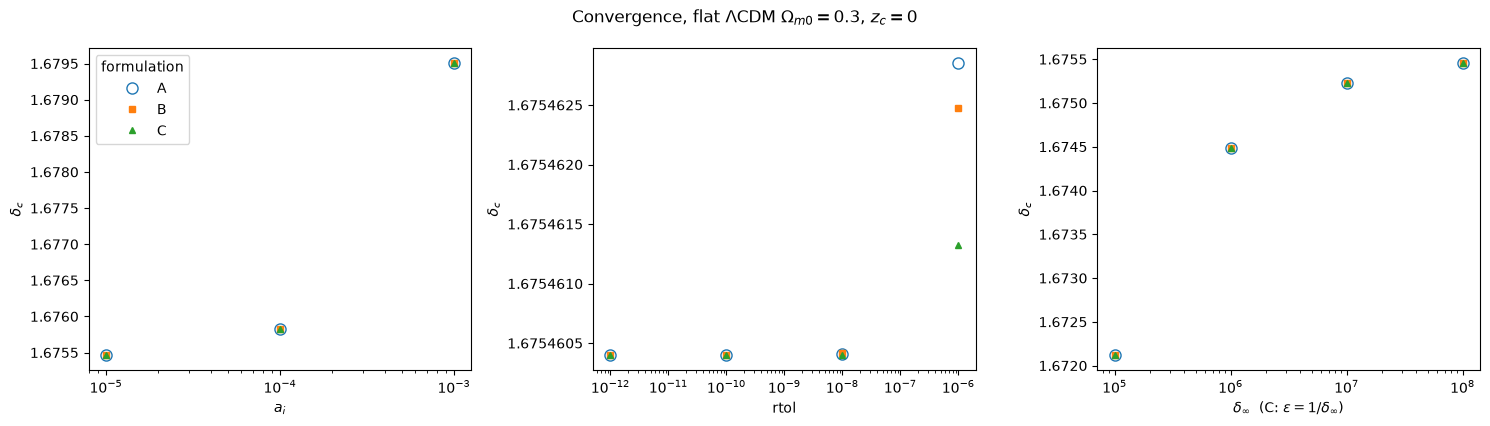

a_i = 1e-03  rtol = 1e-10  delta_inf = 1e+08:  max diff A,B,C in delta_c = 5.8e-11  max event residual = 5.9e-15
a_i = 1e-04  rtol = 1e-10  delta_inf = 1e+08:  max diff A,B,C in delta_c = 5.5e-11  max event residual = 5.1e-15
a_i = 1e-05  rtol = 1e-10  delta_inf = 1e+08:  max diff A,B,C in delta_c = 5.1e-11  max event residual = 3.1e-15
a_i = 1e-05  rtol = 1e-06  delta_inf = 1e+08:  max diff A,B,C in delta_c = 9.2e-07  max event residual = 1.5e-14
a_i = 1e-05  rtol = 1e-08  delta_inf = 1e+08:  max diff A,B,C in delta_c = 6.0e-09  max event residual = 4.9e-15
a_i = 1e-05  rtol = 1e-12  delta_inf = 1e+08:  max diff A,B,C in delta_c = 1.7e-13  max event residual = 2.4e-15
a_i = 1e-05  rtol = 1e-10  delta_inf = 1e+05:  max diff A,B,C in delta_c = 5.1e-11  max event residual = 4.6e-15
a_i = 1e-05  rtol = 1e-10  delta_inf = 1e+06:  max diff A,B,C in delta_c = 5.1e-11  max event residual = 4.0e-15
a_i = 1e-05  rtol = 1e-10  delta_inf = 1e+07:  max diff A,B,C in delta_c = 5.1e-11  max event re

In [15]:
conv = convergence()
plot_convergence(conv, save=False); plt.show()

for row in cross_differences(conv):
    print(f"a_i = {row['a_i']:.0e}  rtol = {row['rtol']:.0e}  delta_inf = {row['delta_inf']:.0e}:  "
          f"max diff A,B,C in delta_c = {row['rel_diff_delta_c']:.1e}  max event residual = {row['max_event_residual']:.1e}")

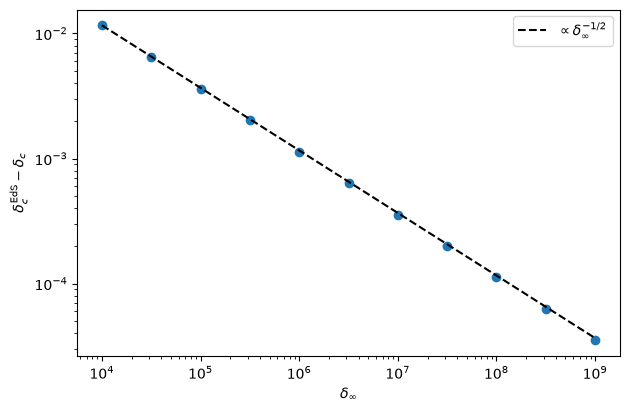

In [ ]:
# Finite-threshold limit in EdS, with a_i small enough that the initial-mode error is small
eds = Cosmology(1.0)
d_infs = np.logspace(4, 9, 11)
deficit = [DELTA_C_EDS - collapse(form_B, eds, 1.0, a_i=1e-7, threshold=d, rtol=1e-12, atol=1e-21)['delta_c']
           for d in d_infs]
fig, ax = plt.subplots(figsize=(7, 4.5))
ax.loglog(d_infs, deficit, 'o')
ax.loglog(d_infs, deficit[0] * (d_infs / d_infs[0])**-0.5, 'k--', label=r'$\propto \delta_\infty^{-1/2}$')
ax.set_xlabel(r'$\delta_\infty$'); ax.set_ylabel(r'$\delta_c^\mathrm{EdS} - \delta_c$'); ax.legend()
plt.show()